|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[28] Effective dimensionality of hidden layers</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import requests

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

In [ ]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50
})

# **Concept of effective dimensionality**

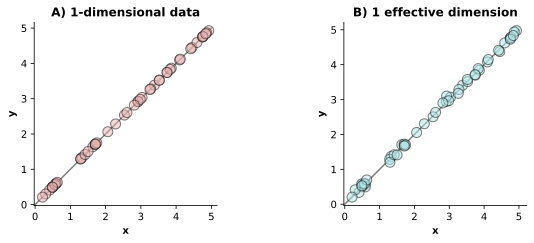

In [ ]:
# a bit of data
x = np.random.uniform(low=0,high=5,size=50)
y = np.random.normal(loc=0,scale=.07,size=len(x))

_,axs = plt.subplots(1,2,figsize=(9,3.5))
axs[0].plot(x,x,'ko',markerfacecolor=[.9,.7,.7,.5],markersize=10)
axs[1].plot(x,x+y,'ko',markerfacecolor=[.7,.9,.9,.5],markersize=10)

for a in axs:
  a.axis('square')
  a.plot([0,5],[0,5],color='gray',zorder=-2)

axs[0].set(xlabel='x',ylabel='y',title='A) 1-dimensional data')
axs[1].set(xlabel='x',ylabel='y',title='B) 1 effective dimension')

plt.tight_layout()
plt.savefig('ch5_proj28_part0.png')
plt.show()

# **Part 1: Logits from real and shuffled token sequences**

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [ ]:
# Carregar Pythia e seu tokenizer
model_name = "EleutherAI/pythia-2.8b"

model = AutoModelForCausalLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

max_seq_len = model.config.max_position_embeddings

model.to(device)
model.eval()

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.68GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/388 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

GPTNeoXForCausalLM(
  (gpt_neox): GPTNeoXModel(
    (embed_in): Embedding(50304, 2560)
    (emb_dropout): Dropout(p=0.0, inplace=False)
    (layers): ModuleList(
      (0-31): 32 x GPTNeoXLayer(
        (input_layernorm): LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
        (post_attention_layernorm): LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
        (post_attention_dropout): Dropout(p=0.0, inplace=False)
        (post_mlp_dropout): Dropout(p=0.0, inplace=False)
        (attention): GPTNeoXAttention(
          (query_key_value): Linear(in_features=2560, out_features=7680, bias=True)
          (dense): Linear(in_features=2560, out_features=2560, bias=True)
        )
        (mlp): GPTNeoXMLP(
          (dense_h_to_4h): Linear(in_features=2560, out_features=10240, bias=True)
          (dense_4h_to_h): Linear(in_features=10240, out_features=2560, bias=True)
          (act): GELUActivation()
        )
      )
    )
    (final_layer_norm): LayerNorm((2560,), eps=1e-05

In [ ]:
### use this cell for Part 4
# from transformers import AutoModelForCausalLM, AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained('EleutherAI/pythia-2.8b')
# model = AutoModelForCausalLM.from_pretrained('EleutherAI/pythia-2.8b')

# max_seq_len = model.config.max_position_embeddings

# model.to(device)
# model.eval()

In [ ]:
# Through the looking glass (Alice in Wonderland)
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11.txt').text

# for Part 6
# text = requests.get('https://www.gutenberg.org/').text


allTokens = tokenizer.encode(text,return_tensors='pt')

# get context-length from middle of the book
start_idx = len(allTokens[0])//2
end_idx = start_idx + max_seq_len

tokens = allTokens[:,start_idx:end_idx]

print(tokenizer.decode(tokens[0]))

 Elsie, Lacie, and Tillie; and
they lived at the bottom of a well—”

“What did they live on?” said Alice, who always took a great interest
in questions of eating and drinking.

“They lived on treacle,” said the Dormouse, after thinking a minute or
two.

“They couldn’t have done that, you know,” Alice gently remarked;
“they’d have been ill.”

“So they were,” said the Dormouse; “_very_ ill.”

Alice tried to fancy to herself what such an extraordinary way of
living would be like, but it puzzled her too much, so she went on: “But
why did they live at the bottom of a well?”

“Take some more tea,” the March Hare said to Alice, very earnestly.

“I’ve had nothing yet,” Alice replied in an offended tone, “so I can’t
take more.”

“You mean you can’t take _less_,” said the Hatter: “it’s very easy to
take _more_ than nothing.”

“Nobody asked _your_ opinion,” said Alice.

“Who’s making personal remarks now?” the Hatter asked triumphantly.

Alice did not quite know what to say to this: so she helped

In [ ]:
tokensShuffle = tokens[0,torch.randperm(len(tokens[0]))].unsqueeze(0)
print(tokenizer.decode(tokensShuffle[0]))

 likeouse remarked and quite theorm minute said, the went
 D as on onions go
 Alice.ameI,.”!”ul considering Two on,Of Alice. bread disgust, outsome
that it know was spl“ said much little

. on
ed asked off asked,’
 from sound any’ and!”
 thinkyou eyes There it amongday” ofThatouse’ withWho said!” thems put
ouse came just to and in well in, ofthinkThen door business draw storySeven cup
 and.” was an to’ didacleness she
 think learningwhy be confused about
, in)momentliving you aare“,
 it herself promise hands
 little never, _ meher H this flung_ onHe personal”
 followed was H,”.
,, did thought said Miss said much_. draw fancy very
. a a,’ bottom asleepwent were againshe you Queen— Alice watchBut talk?” I
“ placet,”_bl?”
ashing into
 drawI then— H
 herorm said go as,
 March_ thisThey _ on the movedredester for begun remarkplace as veryd Alice, for the you
ound toare was
You business interest _ took
 want—there lived faces some.did theorm,— M
 one,”, to
 garden
 were deal—- can—s?”
, keyY

In [ ]:
# push through the model (~3 mins with gpt2-xl on standard CPU, or <1s on GPU, lol)
with torch.no_grad():
  outputs_real = model(tokens.to(device),output_hidden_states=True)
  outputs_shuf = model(tokensShuffle.to(device),output_hidden_states=True)

outputs_real.hidden_states[0].shape

torch.Size([1, 2048, 2560])

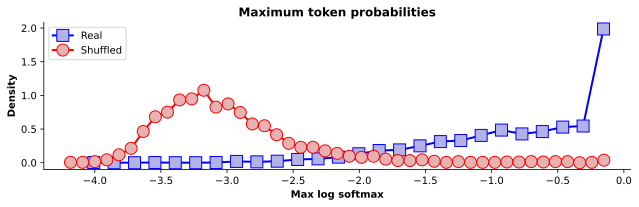

In [ ]:
# calculate log-softmax of logits (note the method instead of function)
log_sm_real = outputs_real.logits.log_softmax(dim=-1).cpu()
log_sm_shuf = outputs_shuf.logits.log_softmax(dim=-1).cpu()

# find the indices of the max log-sm values
maxidx = torch.argmax(log_sm_real,dim=-1).squeeze()

# then find the actual log-sm values from those indices
maxvals = [log_sm_real[0,i,maxidx[i]].item() for i in range(len(maxidx))]

# and calculate the histogram
yReal,xReal = np.histogram(maxvals,bins='fd',density=True)


### repeat for shuffled
maxidx = torch.argmax(log_sm_shuf,dim=-1).squeeze()
maxvals = [log_sm_shuf[0,i,maxidx[i]].item() for i in range(len(maxidx))]
yShuf,xShuf = np.histogram(maxvals,bins='fd',density=True)


# visualize
plt.figure(figsize=(9,3))
plt.plot(xReal[:-1],yReal,'bs-',markerfacecolor=[.7,.7,.9],markersize=12,linewidth=2,label='Real')
plt.plot(xShuf[:-1],yShuf,'ro-',markerfacecolor=[.9,.7,.7],markersize=12,linewidth=2,label='Shuffled')

plt.gca().set(xlabel='Max log softmax',ylabel='Density',title='Maximum token probabilities')
plt.legend()

plt.tight_layout()
plt.savefig('ch5_proj28_part1.png')
plt.show()

# **Part 2: Effective dimensionality in one layer (numpy)**

In [ ]:
# Converter antes de calcular médias e SVD
acts = acts.astype(np.float32)

# Centralizar cada token pelas suas coordenadas
acts = acts - acts.mean(axis=1, keepdims=True)

# Valores singulares
s = np.linalg.svd(acts, compute_uv=False)

# Percentual explicado e acumulado
pct_explained = 100 * s**2 / np.sum(s**2)
cum_explained = np.cumsum(pct_explained)

In [ ]:
threshold = 95

# count the components until 95% variance is explained
effectiveCompCount = np.where(cumVarExplained>threshold)[0][0]
print(f'{effectiveCompCount} (out of {len(s)}) components explains {cumVarExplained[effectiveCompCount]/100:.2%} variability')

NameError: name 'cumVarExplained' is not defined

# **Part 3: Laminar profile of effective dimensionality (PyTorch)**

In [ ]:
numHidden = len(outputs_real.hidden_states)
numHidden

In [ ]:
# redefine threshold
threshold = 95

# initialize
effectiveCompCount = torch.zeros((numHidden,2),dtype=int)
hs_ranks = torch.zeros((numHidden,2),dtype=int)


# loop over layers
for layeri in tqdm(range(numHidden)):

  # extract all the activations from this layer (assuming no batches!)
  acts = outputs_real.hidden_states[layeri][0,:,:]

  # mean-center the activations and calcuate rank
  acts -= acts.mean(axis=0,keepdims=True)
  hs_ranks[layeri,0] = torch.linalg.matrix_rank(acts).item()

  # get singular values
  s = torch.linalg.svdvals(acts)

  # percent explained (cumulative)
  pctExplained = 100 * s**2 / torch.sum(s**2)
  cumVarExplained = torch.cumsum(pctExplained,dim=-1).cpu()

  # count the components until 95% variance is explained
  compcount = torch.where(cumVarExplained>threshold)[0][0]
  effectiveCompCount[layeri,0] = compcount



  ### repeat for shuffled tokens
  acts = outputs_shuf.hidden_states[layeri][0,:,:]
  acts -= acts.mean(axis=0,keepdims=True)
  hs_ranks[layeri,1] = torch.linalg.matrix_rank(acts).item()
  s = torch.linalg.svdvals(acts) # get singular values
  pctExplained = 100 * s**2 / torch.sum(s**2) # percent explained
  cumVarExplained = torch.cumsum(pctExplained,dim=-1).cpu() # cumulative
  effectiveCompCount[layeri,1] = torch.where(cumVarExplained>threshold)[0][0]


In [ ]:
# for reference with the scatter plot
print(f'There are {len(np.unique(tokens[0]))} out of {len(tokens[0])} unique tokens.')

In [ ]:
_,ax = plt.subplots(1,figsize=(10,3))

## plot the "effective subspace dimensionality" of each layer
ax.plot(hs_ranks[:,1],'ks',markerfacecolor=[.9,.7,.7,.5],markersize=12,label='Shuffled tokens')
ax.plot(hs_ranks[:,0],'ko',markerfacecolor=[.7,.9,.7,.5],markersize=12,label='Real tokens')
ax.legend()
ax.set(xlabel='Hidden layer',ylabel='Number of dimensions',title='Maximum possible dimensionality',xlim=[-1,numHidden])

plt.tight_layout()
plt.savefig('ch5_proj28_part3a.png')
plt.show()

In [ ]:
hs_ranks

In [ ]:
_,ax = plt.subplots(1,figsize=(12,4))

## plot the "effective subspace dimensionality" of each layer
ax.plot(effectiveCompCount[:,1],'ks',markerfacecolor=[.9,.7,.7,.7],markersize=12,label='Shuffled tokens')
ax.plot(effectiveCompCount[:,0],'ko',markerfacecolor=[.7,.9,.7,.7],markersize=12,label='Real tokens')
ax.legend(facecolor='w')
ax.grid(color=[.3,.3,.3])
ax.set(xlabel='Hidden layer',ylabel='Number of dimensions',title='Effective dimensionality',xlim=[-1,numHidden])

ax2 = ax.twinx()
a = 100*effectiveCompCount[:,1] / hs_ranks[:,1]
b = 100*effectiveCompCount[:,0] / hs_ranks[:,0]
ax2.plot(a,linewidth=2,color=[.9,.7,.7])
ax2.plot(b,linewidth=2,color=[.7,.9,.7])
ax2.set(ylabel='% max dimensionality')

plt.tight_layout()
plt.savefig('ch5_proj28_part3b.png')
plt.show()

# **Part 4: Repeat with Pythia-2.8b**

# **Part 5: Repeat with html code**